# 02 - Model A: Standard CNN

Build, train, and evaluate **Model A** (a standard CNN: interleaved `Conv2D` + `MaxPooling2D` layers) on the same Intel Image Classification splits cached by `01_data_preparation.ipynb` (teammate 1), and save results using the same Drive-based conventions, so everything can be compared directly in `08_final_comparison.ipynb`.

In [1]:
# --- Environment setup (Google Colab + shared Google Drive, with a local fallback) ---
import os

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Mount the team's shared Drive - this is where 01_data_preparation.ipynb
    # cached the resized/normalized dataset, and where we save checkpoints +
    # results so nobody has to download large files to their own PC.
    drive.mount("/content/drive")
    REPO_DIR = "/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN"
else:
    # Not in Colab - use this repo's own local folders instead of Drive.
    REPO_DIR = os.path.abspath("..")

print("IN_COLAB:", IN_COLAB)
print("REPO_DIR:", REPO_DIR)


Mounted at /content/drive
IN_COLAB: True
REPO_DIR: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN


## 1. Config

In [ ]:
# --- Config for this notebook (defined here, not in a shared file) ---
CONFIG = {
    "image_size": 64,          # resolution of the cached dataset (<= 64x64 per spec)
    "channels": 3,
    "train_ratio": 0.70,
    "val_ratio": 0.15,
    "test_ratio": 0.15,
    "random_seed": 42,
    "batch_size": 32,
    "epochs": 20,               # assignment requires >= 20 epochs
    "learning_rate": 0.001,     # Adam
    "dataset_name": "Intel Image Classification",
    "num_classes": 6,
    "class_names": ["buildings", "forest", "glacier", "mountain", "sea", "street"],
}


# --- Paths ---
PROCESSED_DIR = os.path.join(REPO_DIR, "data", "processed", "intel-image-classification")
CHECKPOINT_DIR = os.path.join(REPO_DIR, "models", "checkpoints", "model_a")
FINAL_MODEL_DIR = os.path.join(REPO_DIR, "models", "final")
FIGURES_DIR = os.path.join(REPO_DIR, "results", "figures", "model_a")
CONFUSION_DIR = os.path.join(REPO_DIR, "results", "confusion_matrices")
METRICS_DIR = os.path.join(REPO_DIR, "results", "metrics")

for d in (CHECKPOINT_DIR, FINAL_MODEL_DIR, FIGURES_DIR, CONFUSION_DIR, METRICS_DIR):
    os.makedirs(d, exist_ok=True)

print("PROCESSED_DIR:", PROCESSED_DIR)
CONFIG


PROCESSED_DIR: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/data/processed/intel-image-classification


{'image_size': 64,
 'channels': 3,
 'train_ratio': 0.7,
 'val_ratio': 0.15,
 'test_ratio': 0.15,
 'random_seed': 42,
 'batch_size': 32,
 'epochs': 20,
 'learning_rate': 0.001,
 'dataset_name': 'Intel Image Classification',
 'num_classes': 6,
 'class_names': ['buildings',
  'forest',
  'glacier',
  'mountain',
  'sea',
  'street']}

## 2. Imports

In [3]:
import json
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Seed

In [4]:
SEED = CONFIG["random_seed"]
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## 4. Load Prepared Data

In [5]:
# Load the same 64x64 float32 [0, 1] splits produced by 01_data_preparation.ipynb.
X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
X_val = np.load(os.path.join(PROCESSED_DIR, "X_val.npy"))
y_val = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))
X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))

with open(os.path.join(PROCESSED_DIR, "class_names.json")) as f:
    class_names = json.load(f)
assert class_names == CONFIG["class_names"], "class_names.json does not match CONFIG - re-check notebook 01"

print("train/val/test sizes:", len(X_train), len(X_val), len(X_test))
print("image shape:", X_train.shape[1:], "dtype:", X_train.dtype)


train/val/test sizes: 11923 2555 2556
image shape: (64, 64, 3) dtype: float32


## 5. Build Model A

In [6]:
def conv_block(filters):
    """Conv2D -> BatchNorm -> ReLU -> MaxPool. `use_bias=False` on the conv
    is standard practice with BatchNorm: BN\'s own learned shift (beta)
    makes the conv bias redundant, so we drop it to save a few parameters."""
    return [
        keras.layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(),
        keras.layers.Activation("relu"),
        keras.layers.MaxPooling2D(pool_size=2),
    ]


def build_model_a(input_shape, num_classes):
    """Model A: standard CNN - interleaved Conv2D and MaxPooling2D layers
    (see Figure 1 in the brief), strengthened with:
      - BatchNormalization after every Conv2D/Dense - stabilizes and speeds
        up training, and acts as a mild regularizer.
      - Light data augmentation (flip/rotate/zoom) - Keras preprocessing
        layers that only apply during training (a no-op at inference/
        predict), combating overfitting on ~12k training images.
      - A 4th, deeper conv block (256 filters) - more representational
        capacity than the original 3-block version.
      - Dropout(0.5) before the output layer for further regularization.
    """
    layers = [
        keras.layers.Input(shape=input_shape),
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(0.05),
        keras.layers.RandomZoom(0.1),
    ]
    for filters in (32, 64, 128, 256):
        layers += conv_block(filters)
    layers += [
        keras.layers.Flatten(),
        keras.layers.Dense(256, use_bias=False),
        keras.layers.BatchNormalization(),
        keras.layers.Activation("relu"),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
    return keras.Sequential(layers, name="model_a_standard_cnn")


input_shape = (CONFIG["image_size"], CONFIG["image_size"], CONFIG["channels"])
model = build_model_a(input_shape, CONFIG["num_classes"])


## 6. Model Summary

In [7]:
model.summary()


Model: "model_a_standard_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,440,998 (5.50 MB)

 Trainable params: 1,439,526 (5.49 MB)

 Non-trainable params: 1,472 (5.75 KB)

## 7. Parameter Count

In [8]:
total_params = model.count_params()
print(f"Total trainable parameters: {total_params:,}")


Total trainable parameters: 1,440,998


## 8. Activation Function Justification

**ReLU** (`max(0, x)`) is used in every hidden `Conv2D`/`Dense` layer, and **softmax** only at the output layer (required to produce a multi-class probability distribution).

- ReLU is a single comparison-and-clamp operation - no exponential - so it is far cheaper to evaluate on constrained/edge hardware than `sigmoid`/`tanh`, both of which require an exponential per activation, across every pixel of every feature map.
- ReLU also avoids the vanishing-gradient problem `sigmoid`/`tanh` suffer from as networks get deeper, which matters here since Model A now stacks four convolutional stages.
- Softmax's exponential cost is negligible in comparison: it is evaluated once per forward pass over only `num_classes` (6) values, not per feature-map pixel like the hidden-layer activations.
- **BatchNormalization** is cheap on hardware too: at inference it reduces to a fixed per-channel affine transform (`scale * x + shift`) using stored running statistics, which is typically fused directly into the preceding convolution's weights by the inference runtime - i.e. it adds effectively zero extra cost at deployment time, while meaningfully speeding up and stabilizing training.

## 9. Training (>= 20 epochs)

In [9]:
ckpt_path = os.path.join(CHECKPOINT_DIR, "best.keras")

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    ckpt_path, monitor="val_loss", save_best_only=True, verbose=1,
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=CONFIG["batch_size"],
    epochs=CONFIG["epochs"],
    shuffle=True,
    callbacks=[checkpoint_cb],
)
total_time = time.time() - t0
avg_time_per_epoch = total_time / CONFIG["epochs"]
print(f"Training ({CONFIG['epochs']} epochs) took {total_time:.1f}s ({avg_time_per_epoch:.1f}s/epoch)")

# Reload the best checkpoint (lowest val_loss, not necessarily the last epoch) before evaluating.
model = keras.models.load_model(ckpt_path)


Epoch 1/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5727 - loss: 1.2031
Epoch 1: val_loss improved from None to 1.02689, saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/model_a/best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/model_a/best.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.6337 - loss: 1.0014 - val_accuracy: 0.5953 - val_loss: 1.0269
Epoch 2/20
370/373 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7154 - loss: 0.7734
Epoch 2: val_loss did not improve from 1.02689
373/373 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.7295 - loss: 0.7389 - val_accuracy: 0.4125 - val_loss: 1.7572
Epoch 3/20
370/373 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7588 - loss: 0.6739
Epoch 3: val_loss did not improve from 1.02689
373/373 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.7634 - loss: 0.6565 - val_accuracy: 0.4740 - val_loss: 1.5

## 10. Training / Validation Loss Curves

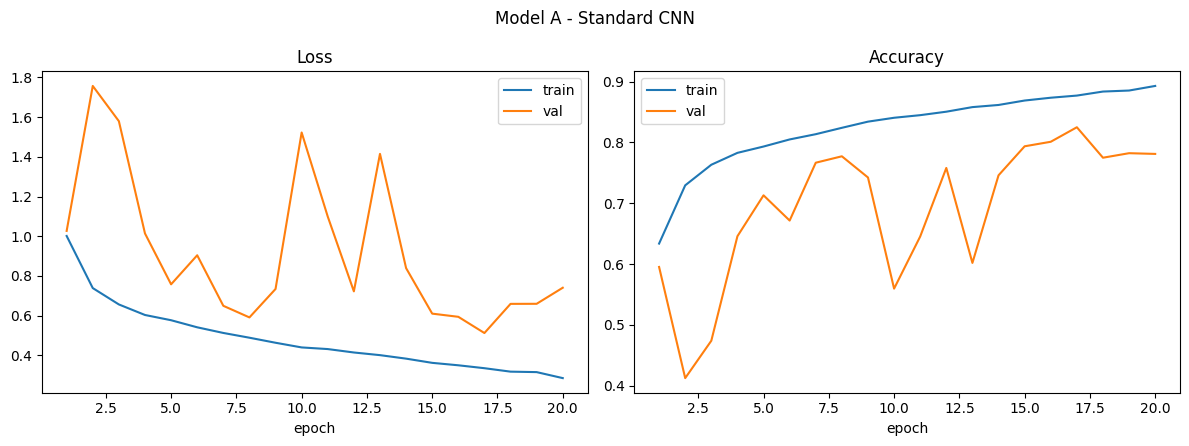

Saved: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/figures/model_a/loss_curve.png


In [10]:
epochs_range = range(1, CONFIG["epochs"] + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs_range, history.history["loss"], label="train")
axes[0].plot(epochs_range, history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs_range, history.history["accuracy"], label="train")
axes[1].plot(epochs_range, history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.suptitle("Model A - Standard CNN")
plt.tight_layout()
loss_curve_path = os.path.join(FIGURES_DIR, "loss_curve.png")
plt.savefig(loss_curve_path, dpi=150)
plt.show()
print("Saved:", loss_curve_path)


## 11. Test Set Evaluation

In [11]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision_macro = precision_score(y_test, y_pred, average="macro")
test_recall_macro = recall_score(y_test, y_pred, average="macro")
cm = confusion_matrix(y_test, y_pred)

print(f"Test accuracy:           {test_accuracy:.4f}")
print(f"Test precision (macro):  {test_precision_macro:.4f}")
print(f"Test recall (macro):     {test_recall_macro:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=class_names))


80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Test accuracy:           0.8208
Test precision (macro):  0.8401
Test recall (macro):     0.8236

              precision    recall  f1-score   support

   buildings       0.64      0.95      0.76       394
      forest       0.98      0.92      0.95       412
     glacier       0.84      0.75      0.79       444
    mountain       0.79      0.82      0.80       456
         sea       0.88      0.77      0.82       417
      street       0.91      0.73      0.81       433

    accuracy                           0.82      2556
   macro avg       0.84      0.82      0.82      2556
weighted avg       0.84      0.82      0.82      2556



## 12. Confusion Matrix

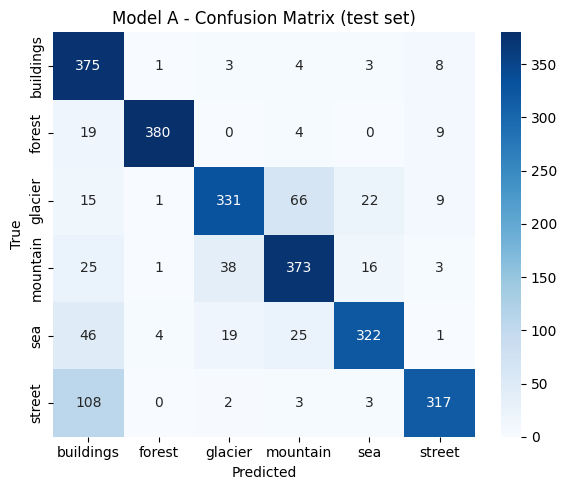

Saved: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/confusion_matrices/model_a.png


In [12]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Model A - Confusion Matrix (test set)")
plt.tight_layout()
cm_path = os.path.join(CONFUSION_DIR, "model_a.png")
plt.savefig(cm_path, dpi=150)
plt.show()
print("Saved:", cm_path)


## 13. Model Size & Training Time

In [13]:
final_model_path = os.path.join(FINAL_MODEL_DIR, "model_a.keras")
model.save(final_model_path)

model_size_kb = os.path.getsize(final_model_path) / 1024
print(f"Saved final model to: {final_model_path}")
print(f"Model size on disk: {model_size_kb:.1f} KB")
print(f"Average training time per epoch: {avg_time_per_epoch:.1f}s")


Saved final model to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/final/model_a.keras
Model size on disk: 16969.1 KB
Average training time per epoch: 9.4s


## 14. Save Results

In [14]:
metrics = {
    "model_name": "Model A (Standard CNN)",
    "dataset_name": CONFIG["dataset_name"],
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(test_precision_macro),
    "test_recall_macro": float(test_recall_macro),
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
    "total_params": int(total_params),
    "model_size_kb": float(model_size_kb),
    "epochs": CONFIG["epochs"],
    "avg_time_per_epoch_sec": float(avg_time_per_epoch),
    "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
}

metrics_path = os.path.join(METRICS_DIR, "model_a.json")
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved metrics to:", metrics_path)


Saved metrics to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/metrics/model_a.json


## 15. Conclusion

In [15]:
print(
    f"Model A (Standard CNN, {CONFIG['image_size']}x{CONFIG['image_size']} input):\n"
    f"  Test accuracy:                  {test_accuracy:.4f}\n"
    f"  Test precision/recall (macro):  {test_precision_macro:.4f} / {test_recall_macro:.4f}\n"
    f"  Total parameters:               {total_params:,}\n"
    f"  Model size on disk:             {model_size_kb:.1f} KB\n"
    f"  Avg. time/epoch:                {avg_time_per_epoch:.1f}s"
)


Model A (Standard CNN, 64x64 input):
  Test accuracy:                  0.8208
  Test precision/recall (macro):  0.8401 / 0.8236
  Total parameters:               1,440,998
  Model size on disk:             16969.1 KB
  Avg. time/epoch:                9.4s
